# Case study: Early economy of the Mirage league

The main analysis of historical leagues has been completed using a consistent analytical pipeline including data preparation, exploratory analysis, economic indicators, PCA, and clustering methods. However, during the course of the project, a new Path of Exile league, **Mirage**, was released on March 6. At the time of completing the analysis, only seven days of market data were available for this league.

Because the dataset for the Mirage league is still limited, it was not included in the main historical analysis to avoid methodological inconsistencies. Instead, it is analysed separately as a case study focusing on the early phase - **launch hype**- of league economies.

To ensure comparability, the same economic indicators used in the main analysis are calculated for the first seven days of all leagues, including Mirage. This allows the early economic structure of the new league to be compared with the early-stage economies of previous leagues. The new league is then projected into the existing analytical framework using PCA and clustering methods, which makes it possible to determine whether its early market dynamics resemble any of the previously identified types of league economies.

This case study therefore serves as an exploratory extension of the project and demonstrates how the developed analytical framework can be applied to analyse the economic characteristics of newly released leagues.

### Importing libraries

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from adjustText import adjust_text
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

### Importing data

In [2]:
#importing already processed datasets for items and players
items= pd.read_csv("../data/items_data_processed/items_processed_day.csv", sep=";", low_memory=False)
players = pd.read_csv("../data/players_data_processed/players_processed_day.csv", sep=";", low_memory=False)

#imporing new datasets for items and players
items_mirage= pd.read_csv("../data/items_data_raw/Mirage.items.csv", sep=";", low_memory=False)
players_mirage= pd.read_csv("../data/players_data_raw/players_mirage.csv", sep=";", low_memory=False)

## Minimal cleaning of new datasets
Preparing the data only doing what is needed for the case study analysis

### Players new data

In [3]:
# add Day column

#adding date column
players_mirage["Date"] = pd.to_datetime(players_mirage["Date"])
league_start = players_mirage.groupby("League")["Date"].transform("min")
players_mirage["Day"] = (players_mirage["Date"]-league_start).dt.days + 1
players_mirage

,League,Date,Players,Day
0,Mirage,2026-03-06,190653.0,1
1,Mirage,2026-03-07,158206.0,2
2,Mirage,2026-03-08,156804.0,3
3,Mirage,2026-03-09,135034.0,4
4,Mirage,2026-03-10,127003.0,5
5,Mirage,2026-03-11,120098.0,6
6,Mirage,2026-03-12,114171.0,7


### Items new data

In [4]:
# making sure that League column is consistent across datasets
items_mirage["League"] = "Mirage"

In [5]:
#removing unnecessary columns
items_mirage = items_mirage.drop(columns=['Id','Variant','BaseType'])
items_mirage

,League,Date,Type,Name,Links,Value,Confidence
0,Mirage,2026-03-07,Oil,Prismatic Oil,NaN,90.81,Low
1,Mirage,2026-03-08,Oil,Prismatic Oil,NaN,16.00,Medium
2,Mirage,2026-03-09,Oil,Prismatic Oil,NaN,32.00,Medium
3,Mirage,2026-03-10,Oil,Prismatic Oil,NaN,47.00,Medium
4,Mirage,2026-03-11,Oil,Prismatic Oil,NaN,50.00,High
...,...,...,...,...,...,...,...
200377,Mirage,2026-03-08,ForbiddenJewel,Lesson of the Seasons,NaN,9.55,High
200378,Mirage,2026-03-09,ForbiddenJewel,Lesson of the Seasons,NaN,10.00,High
200379,Mirage,2026-03-10,ForbiddenJewel,Lesson of the Seasons,NaN,9.10,High
200380,Mirage,2026-03-11,ForbiddenJewel,Lesson of the Seasons,NaN,7.00,High


Because the initial operations on the **Date column** produced an error, the column was checked for unusual or incorrect values.

In [6]:
#bad records with wrong date 
items_mirage[~items_mirage["Date"].str.contains("2026", na=False)].copy()

,League,Date,Type,Name,Links,Value,Confidence
39435,Mirage,Flameblast,NaN,2.0,NaN,NaN,NaN
46581,Mirage,Frozen Legion,NaN,2.0,NaN,NaN,NaN
47003,Mirage,Icicle Mine,1/20,NaN,NaN,NaN,NaN
47258,Mirage,SkillGem,Flamewood Support,20,High,NaN,NaN
47351,Mirage,Sacrifice Support,NaN,2.0,NaN,NaN,NaN
53907,Mirage,Expert Retaliation Support,NaN,2.0,NaN,NaN,NaN
54256,Mirage,Creeping Frost,NaN,2.0,NaN,NaN,NaN
54619,Mirage,SkillGem,Rage Vortex,1/23c,High,NaN,NaN
68273,Mirage,Medium,NaN,NaN,NaN,NaN,NaN
70608,Mirage,Summon Chaos Golem,20c,NaN,NaN,NaN,NaN


These records are incorrect and do not contain valid information such as item name, price, or confidence level. In these cases, the item type and name were mixed and mistakenly merged into the date column, resulting in corrupted entries. As these records do not contain usable information, they were removed from the dataset.

In [7]:
#removing bad records
items_mirage["Date"] = pd.to_datetime(items_mirage["Date"], errors="coerce")
items_mirage = items_mirage.dropna(subset=["Date"])

In [8]:
#add Day column
items_mirage = items_mirage.copy()
items_mirage["Date"] = pd.to_datetime(items_mirage["Date"])
league_start = items_mirage.groupby("League")["Date"].transform("min")
items_mirage["Day"] = (items_mirage["Date"]-league_start).dt.days + 1

In [9]:
# Filtering records with 5 and 6 links (keeping only base versions)
items_mirage = items_mirage[~items_mirage["Links"].isin(["5 links", "6 links"])]
items_mirage

,League,Date,Type,Name,Links,Value,Confidence,Day
0,Mirage,2026-03-07,Oil,Prismatic Oil,NaN,90.81,Low,3
1,Mirage,2026-03-08,Oil,Prismatic Oil,NaN,16.00,Medium,4
2,Mirage,2026-03-09,Oil,Prismatic Oil,NaN,32.00,Medium,5
3,Mirage,2026-03-10,Oil,Prismatic Oil,NaN,47.00,Medium,6
4,Mirage,2026-03-11,Oil,Prismatic Oil,NaN,50.00,High,7
...,...,...,...,...,...,...,...,...
200377,Mirage,2026-03-08,ForbiddenJewel,Lesson of the Seasons,NaN,9.55,High,4
200378,Mirage,2026-03-09,ForbiddenJewel,Lesson of the Seasons,NaN,10.00,High,5
200379,Mirage,2026-03-10,ForbiddenJewel,Lesson of the Seasons,NaN,9.10,High,6
200380,Mirage,2026-03-11,ForbiddenJewel,Lesson of the Seasons,NaN,7.00,High,7


In [10]:
#drop links column
items_mirage = items_mirage.drop(columns=["Links"])

In [11]:
# handling missing values
items_mirage.isna().sum()

League        0
Date          0
Type          0
Name          0
Value         0
Confidence    0
Day           0
dtype: int64

## Merging old and new datasets

In [12]:
items_all = pd.concat([items, items_mirage])
players_all = pd.concat([players, players_mirage])

## League economic indicators - for 7 first days of each league

In [13]:
# filtering first 7 days of each league
items_all = items_all[items_all["Day"] <= 7]
players_all = players_all[players_all["Day"] <= 7]

### Item data aggregation

In [14]:
league_market = (items_all.groupby("League").agg(avg_price=("Value","mean"),median_price=("Value","median"),unique_items=("Name","nunique"),total_market_value=("Value","sum")).reset_index())
avg_daily_listings = (items_all.groupby(["League","Day"]).size().groupby("League").mean().reset_index(name="avg_daily_listings"))

league_market = league_market.merge(avg_daily_listings, on="League")
league_market

,League,avg_price,median_price,unique_items,total_market_value,avg_daily_listings
0,Affliction,47.227888,5.00,3949,6.661021e+06,20148.571429
1,Ancestor,49.245977,6.40,6134,7.933872e+06,23015.285714
2,Keepers,56.651735,4.00,4467,9.412459e+06,23735.142857
3,Mercenaries,58.251932,5.00,4239,9.378736e+06,23000.428571
4,Mirage,111.006930,3.59,4463,1.795482e+07,23106.428571
5,Necropolis,59.677240,5.00,4083,8.845301e+06,21174.142857
6,Settlers,63.822146,5.00,4177,1.046447e+07,23423.285714


### Players data aggregation

In [15]:
league_players = (players_all.groupby("League").agg(mean_daily_players=("Players","mean")).reset_index())
league_players

,League,mean_daily_players
0,Affliction,121784.428571
1,Ancestor,113243.571429
2,Keepers,132576.285714
3,Mercenaries,130558.571429
4,Mirage,143138.428571
5,Necropolis,119227.285714
6,Settlers,173436.285714


### Market Value Concentration

In [16]:
#top 1% item value share
def market_concentration(df):
    total_value = df["Value"].sum()
    top_n = int(len(df) * 0.01)
    top_value = df.nlargest(top_n, "Value")["Value"].sum()

    return pd.Series({"top_value_share": top_value / total_value})

market_concentration = items_all.groupby("League").apply(market_concentration, include_groups=False).reset_index()
market_concentration

,League,top_value_share
0,Affliction,0.578356
1,Ancestor,0.486585
2,Keepers,0.660915
3,Mercenaries,0.582176
4,Mirage,0.656165
5,Necropolis,0.608234
6,Settlers,0.688694


### Merging datasets

In [17]:
league_economy = (league_market.merge(market_concentration, on="League").merge(league_players, on="League"))
league_economy

,League,avg_price,median_price,unique_items,total_market_value,avg_daily_listings,top_value_share,mean_daily_players
0,Affliction,47.227888,5.00,3949,6.661021e+06,20148.571429,0.578356,121784.428571
1,Ancestor,49.245977,6.40,6134,7.933872e+06,23015.285714,0.486585,113243.571429
2,Keepers,56.651735,4.00,4467,9.412459e+06,23735.142857,0.660915,132576.285714
3,Mercenaries,58.251932,5.00,4239,9.378736e+06,23000.428571,0.582176,130558.571429
4,Mirage,111.006930,3.59,4463,1.795482e+07,23106.428571,0.656165,143138.428571
5,Necropolis,59.677240,5.00,4083,8.845301e+06,21174.142857,0.608234,119227.285714
6,Settlers,63.822146,5.00,4177,1.046447e+07,23423.285714,0.688694,173436.285714


### Market indicators per player

In [18]:
league_economy["listings_per_player"] = (league_economy["avg_daily_listings"] / league_economy["mean_daily_players"])
league_economy["market_value_per_player"] = (league_economy["total_market_value"] / league_economy["mean_daily_players"])

league_economy

,League,avg_price,median_price,unique_items,total_market_value,avg_daily_listings,top_value_share,mean_daily_players,listings_per_player,market_value_per_player
0,Affliction,47.227888,5.00,3949,6.661021e+06,20148.571429,0.578356,121784.428571,0.165445,54.695181
1,Ancestor,49.245977,6.40,6134,7.933872e+06,23015.285714,0.486585,113243.571429,0.203237,70.060239
2,Keepers,56.651735,4.00,4467,9.412459e+06,23735.142857,0.660915,132576.285714,0.179030,70.996552
3,Mercenaries,58.251932,5.00,4239,9.378736e+06,23000.428571,0.582176,130558.571429,0.176169,71.835466
4,Mirage,111.006930,3.59,4463,1.795482e+07,23106.428571,0.656165,143138.428571,0.161427,125.436726
5,Necropolis,59.677240,5.00,4083,8.845301e+06,21174.142857,0.608234,119227.285714,0.177595,74.188562
6,Settlers,63.822146,5.00,4177,1.046447e+07,23423.285714,0.688694,173436.285714,0.135054,60.336109


## PCA analysis

### 1. Filtering non-numerical data

In [19]:
pca_indicators=league_economy.drop(columns=["League"])

### 2. Data standarisation

In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_indicators)

### 3. Applying PCA function

In [21]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

### 4. Explained variance of the principal components

Text(0, 0.5, 'Explained variance')

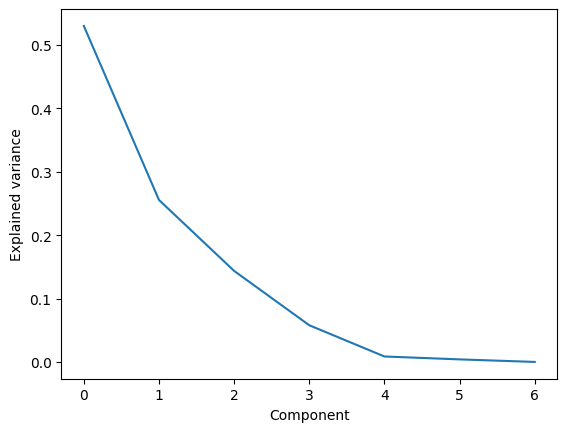

In [22]:
explained_variance = pca.explained_variance_ratio_

plt.plot(explained_variance)
plt.xlabel("Component")
plt.ylabel("Explained variance")

In [23]:
np.cumsum(pca.explained_variance_ratio_)

array([0.53027098, 0.78589205, 0.92953073, 0.98740844, 0.99600087,
       1.        , 1.        ])

In [24]:
#Indicators contributions to the principal components
loadings = pd.DataFrame(pca.components_.T,columns=[f"PC{i+1}" for i in range(pca.components_.shape[0])],index=pca_indicators.columns)

print(loadings)

                              PC1       PC2       PC3       PC4       PC5  \
avg_price                0.387353  0.305984 -0.154674  0.267744 -0.037938   
median_price            -0.388499  0.013139  0.283846  0.545794 -0.299688   
unique_items            -0.222548  0.474134  0.384744  0.161778  0.726742   
total_market_value       0.392324  0.323009 -0.058005  0.198972 -0.072945   
avg_daily_listings       0.175481  0.261290  0.669525 -0.445482 -0.409661   
top_value_share          0.395802 -0.266536  0.085143 -0.303775  0.433765   
mean_daily_players       0.334996 -0.246117  0.468694  0.279624 -0.007412   
listings_per_player     -0.324641  0.404920 -0.123452 -0.429901 -0.078933   
market_value_per_player  0.300853  0.461752 -0.231705  0.104510 -0.114073   

                              PC6       PC7  
avg_price                0.065295  0.624773  
median_price             0.601414 -0.059395  
unique_items            -0.130539 -0.056262  
total_market_value      -0.022661 -0.093737  

### 5. PCA plot

In [25]:
pca_df = pd.DataFrame(X_pca[:, :2], columns=["PC1","PC2"])
pca_df["League"] = league_economy["League"]

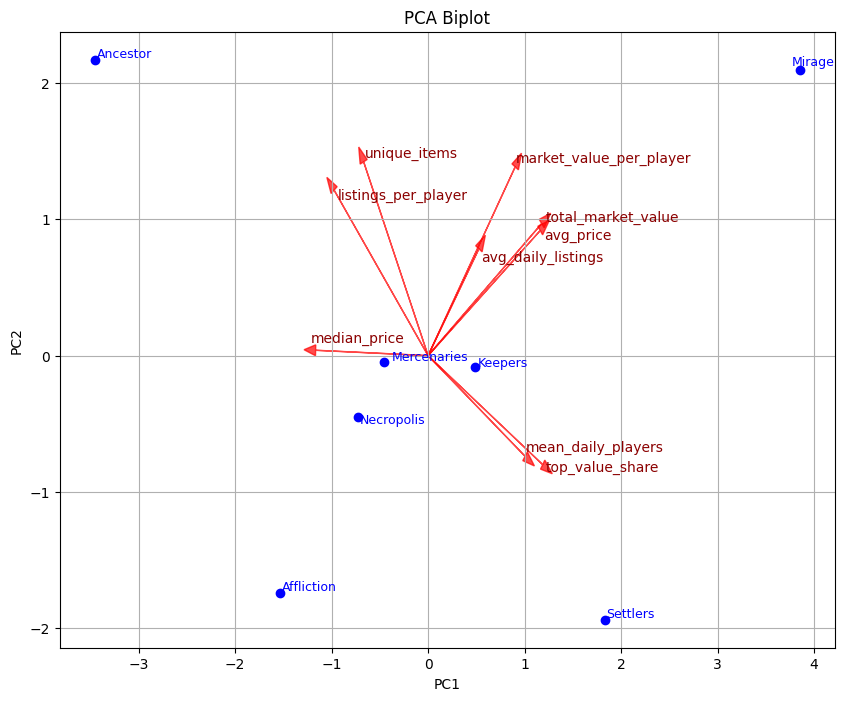

In [26]:
plt.figure(figsize=(10,8))

texts = []

plt.scatter(pca_df["PC1"], pca_df["PC2"], color="blue")

# for leagues names
for i, league in enumerate(pca_df["League"]):
    texts.append(plt.text(pca_df["PC1"][i],pca_df["PC2"][i],league,fontsize=9,color="blue"))

#for arrows
scale = 3

for i, feature in enumerate(pca_indicators.columns):
    x = pca.components_[0, i] * scale
    y = pca.components_[1, i] * scale

    plt.arrow(0, 0, x, y,color='red',alpha=0.7,head_width=0.08)
    texts.append(plt.text(x, y, feature, color='darkred'))

# labels adjustment
adjust_text(texts)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot")
plt.grid()
plt.show()

## Clustering

### K-Means

#### 1. Defining X variable

In [27]:
X = X_pca[:, :3]   # PC1, PC2, PC3

#### 2. Selection of the number of clusters

Best k (Calinski-Harabasz): 6
Best k (Silhouette): 3


<Axes: xlabel='k'>

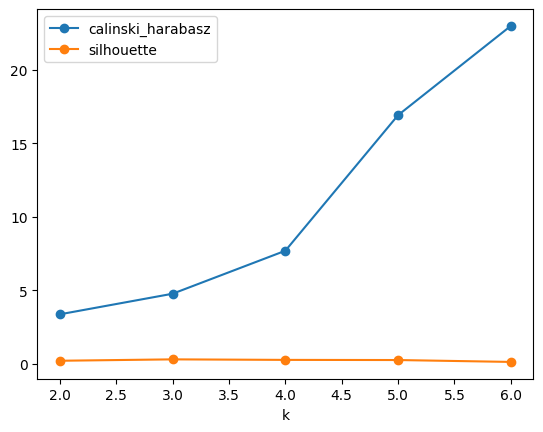

In [28]:
scores = []

for k in range(2, 7): 
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X)
    ch = calinski_harabasz_score(X, km.labels_)
    sil = silhouette_score(X, km.labels_)

    scores.append({'k': k,'calinski_harabasz': ch,'silhouette': sil})

res_df = pd.DataFrame(scores)

best_ch_k = res_df.loc[res_df['calinski_harabasz'].idxmax(), 'k']
best_sil_k = res_df.loc[res_df['silhouette'].idxmax(), 'k']

print(f"Best k (Calinski-Harabasz): {best_ch_k}")
print(f"Best k (Silhouette): {best_sil_k}")

res_df.plot(x='k', y=['calinski_harabasz','silhouette'], marker='o')

The Calinski–Harabasz index increased steadily with higher values ofk, reaching its maximum at k=6  However, given that the dataset contains only seven leagues, this result effectively corresponds to assigning nearly every league to its own cluster. Such a solution provides limited interpretability and therefore is not considered meaningful in the context of this study.

In contrast, the silhouette score suggested a lower number of clusters, indicating three clusters. Because the silhouette score explicitly measures cluster separation and cohesion, it was considered more informative for interpreting the structure of the dataset.

#### 3. Influence of n_init hyperparameter

<Axes: xlabel='n_init'>

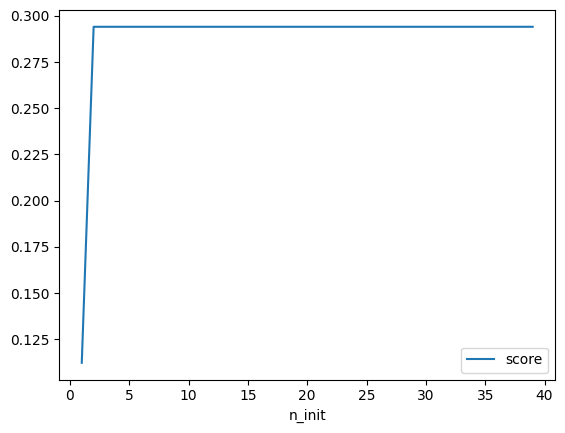

In [29]:
scores = []
for i in range(1, 40):
  kmeans = KMeans(n_clusters=3, random_state=100, n_init=i).fit(X)
  score = silhouette_score(X, kmeans.labels_)
  scores.append({'n_init': i, 'score': score})
pd.DataFrame(scores).plot(x='n_init', y='score')

#### 4. Influence of n_clusters hyperparameter

<Axes: xlabel='n_clusters'>

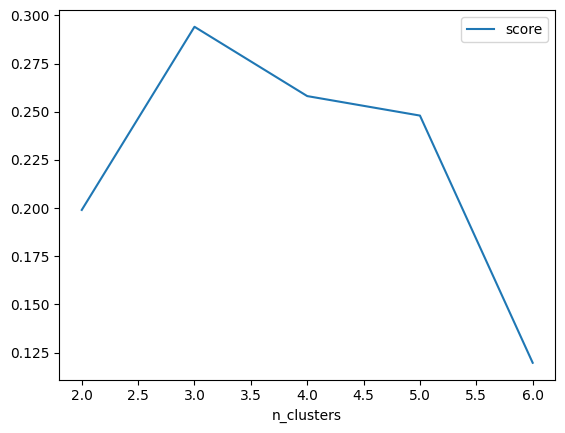

In [30]:
scores = []
for i in range(2, 7):
  kmeans = KMeans(n_clusters=i, random_state=0, n_init=10).fit(X)
  score = silhouette_score(X, kmeans.labels_)
  scores.append({'n_clusters': i, 'score': score})
pd.DataFrame(scores).plot(x='n_clusters', y='score')

#### 5. Clustering

In [31]:
X_cluster = X_pca[:, :2]

kmeans = KMeans(n_clusters=3, random_state=50)
clusters = kmeans.fit_predict(X_cluster)

pca_df["cluster"] = clusters

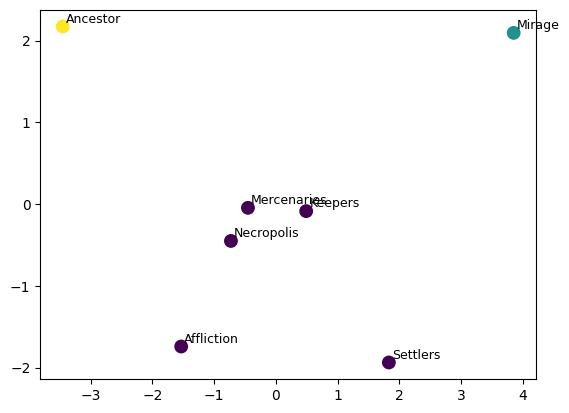

In [32]:
plt.scatter(pca_df["PC1"],pca_df["PC2"],c=pca_df["cluster"],cmap="viridis",s=80)

# for leagues names
for i, league in enumerate(pca_df["League"]):
    plt.text(pca_df["PC1"][i] + 0.05,pca_df["PC2"][i] + 0.05,league,fontsize=9)

The k-means clustering results suggest a three-cluster structure among the analysed league economies.

Visualisation in the space of the first two principal components reveals three distinct groups:
* Mirage and Ancestor cluster which appears clearly separated from all other leagues,
* large cluster consisting of Settlers, Affliction, Keepers, Mercenaries and Necropolis, which display relatively similar economic characteristics.

This structure suggests that the early economy of the **Mirage league** differs significantly from previously observed league economies, while the Ancestor league also exhibits certain unique characteristics compared with the remaining leagues.

### Hierarchical clustering

#### 1. Choosing number of clusters

Best k (Calinski-Harabasz): 6
Best k (Silhouette): 2


<Axes: xlabel='k'>

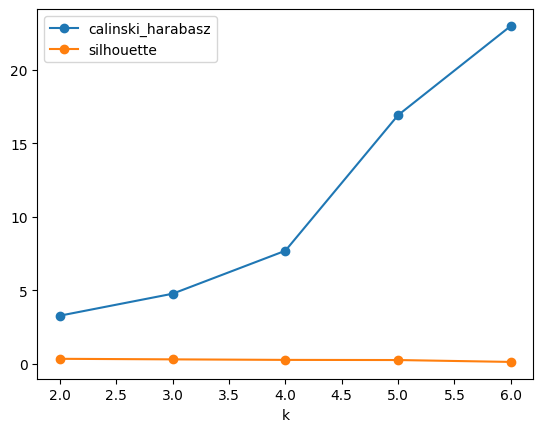

In [33]:
scores = []

for k in range(2, 7):
    hc = AgglomerativeClustering(n_clusters=k)
    labels = hc.fit_predict(X)

    ch = calinski_harabasz_score(X, labels)
    sil = silhouette_score(X, labels)

    scores.append({
        'k': k,
        'calinski_harabasz': ch,
        'silhouette': sil
    })

res_df = pd.DataFrame(scores)

best_ch_k = res_df.loc[res_df['calinski_harabasz'].idxmax(), 'k']
best_sil_k = res_df.loc[res_df['silhouette'].idxmax(), 'k']

print(f"Best k (Calinski-Harabasz): {best_ch_k}")
print(f"Best k (Silhouette): {best_sil_k}")

res_df.plot(x='k', y=['calinski_harabasz', 'silhouette'], marker='o')

<Axes: xlabel='n_clusters'>

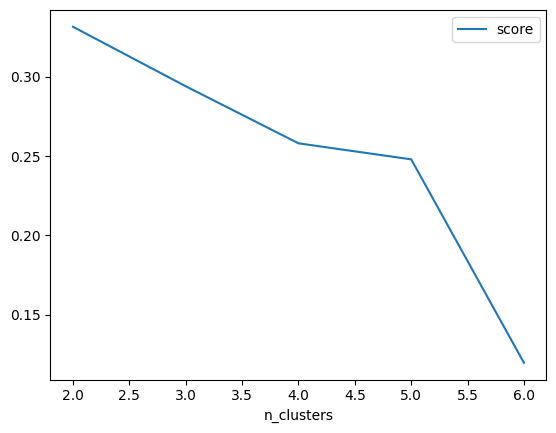

In [34]:
scores = []
for i in range(2, 7):
  kmeans = AgglomerativeClustering(n_clusters=i).fit(X)
  score = silhouette_score(X, kmeans.labels_)
  scores.append({'n_clusters': i, 'score': score})
pd.DataFrame(scores).plot(x='n_clusters', y='score')

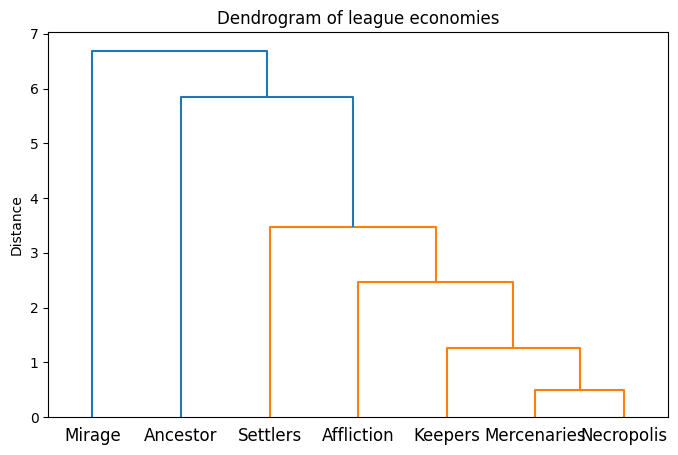

In [35]:
linked = linkage(X_cluster, method="ward")

plt.figure(figsize=(8,5))
dendrogram(linked, labels=pca_df["League"].values)
plt.title("Dendrogram of league economies")
plt.ylabel("Distance")
plt.show()

Both dendogram and the score analysis suggested only 2 clusters in hierarchical approach. 

#### 2. Clustering

In [36]:
agg = AgglomerativeClustering(n_clusters=3)
clusters = agg.fit_predict(X_cluster)

pca_df["agg_cluster"] = clusters

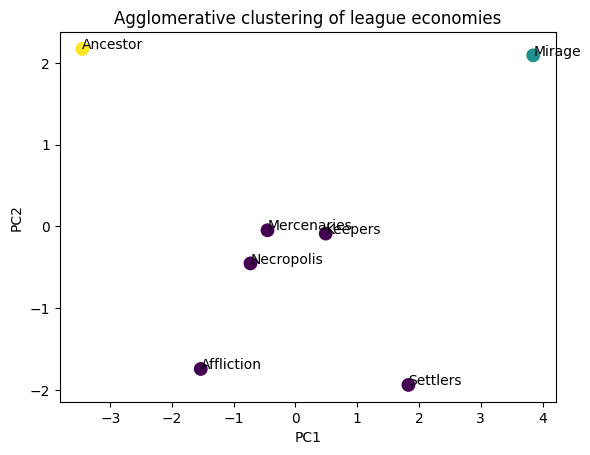

In [37]:
plt.scatter( pca_df["PC1"],pca_df["PC2"],c=pca_df["agg_cluster"],cmap="viridis",s=80)

for i in range(len(pca_df)):
    plt.text( pca_df["PC1"][i],pca_df["PC2"][i], pca_df["League"][i])

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Agglomerative clustering of league economies")
plt.show()


The hierarchical clustering results suggest only two-cluster structure among the analysed league economies:
*the first cluster consists solely of Mirage
*the second cluster includes all remaining leagues.

However, the dendrogram reveals an additional hierarchical structure. In particular, the Ancestor league merges with the other leagues only at a relatively high distance, suggesting that its economic characteristics are also somewhat distinct.Therefore, while hierarchical clustering formally identifies two clusters, the structure of the dendrogram indicates that Ancestor behaves as a partial outlier within the main group.

**Conclusions:**

* This case study analysed the early economic structure of the **Mirage league** in Path of Exile using the same analytical framework applied to historical leagues. To ensure comparability, only the first seven days of market data were considered for all leagues, focusing on the highly volatile launch phase of league economies.

* The clustering analysis revealed that the Mirage league forms a clearly distinct economic profile compared with previous leagues. In both PCA visualisation and clustering results, Mirage appears strongly separated from the remaining leagues, suggesting that its early market dynamics differ significantly from previously observed patterns. The Ancestor league also shows partial divergence, while the remaining leagues form a relatively cohesive group with similar early economic characteristics.

* These results, however, should be interpreted with caution. The dataset contains only a small number of observations, and the analysis focuses on the first days of each league, a period characterised by high market instability and rapid price increase. In addition, at an early stage of the league many values estimates originate from low-confidence listings, which introduces additional noise into the dataset.


Despite these limitations, the results demonstrate that the analytical framework developed in this project can capture meaningful structural differences between league economies even during the early launch phase. The case study therefore illustrates how the methodology can be applied to analyse newly released leagues and compare theireconomic dynamics with historical market patterns.

## Additional analysis – validation of predicted low-investment items in the new league economy

As part of the project, early league price spikes in the economy of Path of Exile were previously analysed. That analysis identified several items that historically experienced the largest price increases during the first days of a league. These early spikes are typically driven by rapid player progression and strong demand for tehse items required in early builds. Based on this historical analysis, a set of items was identified as potential low-investment opportunities at the beginning of a new league, as they repeatedly showed strong early price growth.

In this additional analysis, we evaluate whether those predictions were accurate in the context of the newly released Mirage league. Using the observed price changes during the first days of the league, we assess whether investing in these historically high-growth items would indeed have resulted in profitable outcomes. This provides a practical validation of the predictive insights derived from the earlier analysis of early league price dynamics.

All the potential investment opportunities identified in the analysis belonged to skill gems, which is typical at the beginning of a league, as players aim to quickly progress using their main attack skills.

In [38]:
skill_gems = ["Volatility Support", "Cyclone of Tumult", "Void Manipulation Support", "Vaal Smite", "Arrogance Support", "Vaal Caustic Arrow", "Increased Critical Damage Support", "Rain of Arrows of Saturation", "Storm Brand of Indecision", "Tempest Shield"]

### Early Mirage league price spikes

In [39]:
item_time_series = (items_mirage.groupby(["League", "Name", "Day"])["Value"].median().reset_index())
item_time_series

,League,Name,Day,Value
0,Mirage,+12% to Chaos Resistance,1,1.000
1,Mirage,+12% to Chaos Resistance,2,1.000
2,Mirage,+12% to Chaos Resistance,3,1.000
3,Mirage,+12% to Chaos Resistance,4,1.000
4,Mirage,+12% to Chaos Resistance,5,1.000
...,...,...,...,...
30809,Mirage,Zodiac Leather,4,3.675
30810,Mirage,Zodiac Leather,5,5.000
30811,Mirage,Zodiac Leather,6,5.000
30812,Mirage,Zodiac Leather,7,5.000


In [40]:
price_day1 = (item_time_series.sort_values("Day").groupby(["League","Name"]).first().reset_index())
price_day5 = (item_time_series[item_time_series["Day"] <= 5].sort_values("Day").groupby(["League","Name"]).last().reset_index())

In [41]:
price_spikes = price_day1.merge(price_day5,on=["League","Name"],suffixes=("_day1","_day5"))
price_spikes

,League,Name,Day_day1,Value_day1,Day_day5,Value_day5
0,Mirage,+12% to Chaos Resistance,1,1.0,5,1.0
1,Mirage,+15% to Cold Resistance,1,1.0,5,1.0
2,Mirage,+15% to Fire Resistance,1,1.0,5,1.0
3,Mirage,+15% to Lightning Resistance,1,1.0,5,1.0
4,Mirage,+2% Chance to Block Attack Damage,1,1.0,5,1.0
...,...,...,...,...,...,...
4440,Mirage,Zealotry,2,1.0,5,10.0
4441,Mirage,Zeel's Amplifier,1,1.0,5,1.0
4442,Mirage,Zerphi's Heart,3,303.6,5,113.0
4443,Mirage,Zerphi's Last Breath,2,1.0,5,1.0


In [42]:
price_spikes["price_spike"] = price_spikes["Value_day5"] / price_spikes["Value_day1"]
top_spikes = price_spikes.sort_values("price_spike", ascending=False).head(20).copy()

### Predicted skill gems in the top 20 Mirage early-League price spikes 

In [43]:
matched = top_spikes[top_spikes["Name"].isin(skill_gems)].copy()
matched

,League,Name,Day_day1,Value_day1,Day_day5,Value_day5,price_spike
4169,Mirage,Vaal Smite,2,1.0,5,82.05,82.05
2721,Mirage,Rain of Arrows of Saturation,2,1.0,5,75.00,75.00


### Number of correct predictions 

In [44]:
n_predicted = len(skill_gems)
n_matched = matched["Name"].nunique()

print(f"Matched items: {n_matched} out of {n_predicted}")

Matched items: 2 out of 10


### Potential profit - correctly predicted skill gems in the top20 price spikes of Mirage league

In [45]:
matched["profit"] = matched["Value_day5"] - matched["Value_day1"]
matched["roi"] = matched["Value_day5"] / matched["Value_day1"]
matched[["Name","Value_day1","Value_day5","profit","roi"]].sort_values("roi", ascending=False)

,Name,Value_day1,Value_day5,profit,roi
4169,Vaal Smite,1.0,82.05,81.05,82.05
2721,Rain of Arrows of Saturation,1.0,75.00,74.00,75.00


In [46]:
total_investment = matched["Value_day1"].sum()
total_value = matched["Value_day5"].sum()

profit = total_value - total_investment
roi = total_value / total_investment

print("Total investment:", total_investment)
print("Final value:", total_value)
print("Total profit:", profit)
print("Investment roi", roi)

Total investment: 2.0
Final value: 157.05
Total profit: 155.05
Investment roi 78.525


### Potential profit - all the basket of predicted skill gems

In [47]:
basket = price_spikes[price_spikes["Name"].isin(skill_gems)].copy()

total_investment = basket["Value_day1"].sum()
total_value = basket["Value_day5"].sum()

profit = total_value - total_investment
roi = total_value / total_investment

print(f"Number of items: {len(basket)}")
print(f"Total investment: {total_investment:.2f}")
print(f"Final value: {total_value:.2f}")
print(f"Total profit: {profit:.2f}")
print(f"Basket ROI: {roi:.2f}")

Number of items: 10
Total investment: 13.46
Final value: 380.52
Total profit: 367.07
Basket ROI: 28.28


In [48]:
basket["profit"] = basket["Value_day5"] - basket["Value_day1"]
basket["ROI"] = basket["Value_day5"] / basket["Value_day1"]

basket.sort_values("ROI", ascending=False)[["Name", "Value_day1", "Value_day5", "profit", "ROI"]]

,Name,Value_day1,Value_day5,profit,ROI
4169,Vaal Smite,1.000,82.050,81.050,82.050000
2721,Rain of Arrows of Saturation,1.000,75.000,74.000,75.000000
850,Cyclone of Tumult,3.000,106.600,103.600,35.533333
4271,Volatility Support,0.955,23.500,22.545,24.607330
1962,Increased Critical Damage Support,1.000,21.125,20.125,21.125000
213,Arrogance Support,1.000,15.000,14.000,15.000000
3533,Tempest Shield,1.000,15.000,14.000,15.000000
4254,Void Manipulation Support,1.000,13.000,12.000,13.000000
3362,Storm Brand of Indecision,2.500,28.250,25.750,11.300000
4124,Vaal Caustic Arrow,1.000,1.000,0.000,1.000000


<Axes: ylabel='Name'>

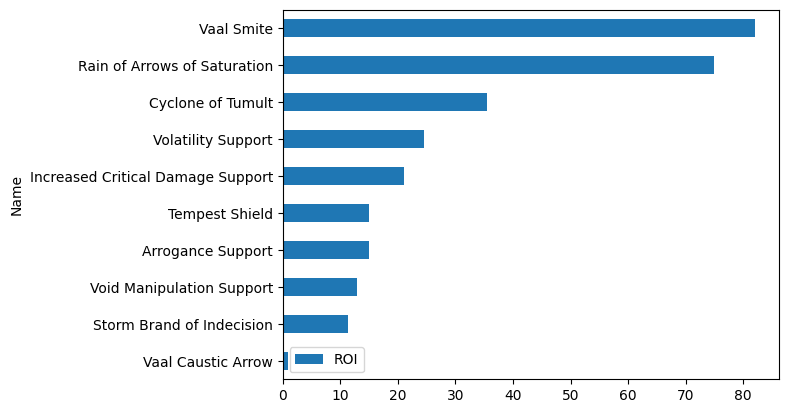

In [49]:
basket.sort_values("ROI").plot.barh(x="Name", y="ROI")

**Conclusions:**

The additional analysis evaluated whether the low-investment items identified from historical early-league price spike patterns also performed well in the Mirage league. 

All predicted investment opportunities belonged to the skill gem category, which confirms a recurring pattern in early league economies. During the first days of a league, players prioritise upgrading their main skills in order to progress quickly, which leads to strong demand for specific gems and significant price increases. 

A simulated investment strategy assuming the purchase of one unit of each predicted gem at the beginning of the league resulted in a very high overall return after five days. While the profitability varied across items, several gems generated particularly strong price growth, confirming that early-league demand for certain skills can create substantial short-term investment opportunities.

Overall, the results suggest that historical early-league price spike patterns can provide useful signals for identifying profitable low-cost investment opportunities in newly released leagues, even during the highly volatile launch phase.